In [8]:
import pandas as pd

# Load dataset
df = pd.read_csv('C:/Users/DELL-7420/OneDrive/Desktop/OCN/User_Data_with_Suggestions(1).csv')

# View first few rows
print(df.head())

   User_ID          Name  Age  Mobile_Number           Occupation  \
0     5658        Sherif   24     8321371910            IT sector   
1     7814  Toni Jebasto   41     7550172586  Other Professionals   
2     4089      Nitheesh   27     8808325710               Doctor   
3     6229     Rishikesh   26     9279039994              Teacher   
4     8383         Rahul   68     6913126492            IT sector   

      Location  Daily_Usage_GB  Daily_Usage_MB  Monthly_Usage_GB Device_Type  \
0   Villupuram            4.29         4392.96             128.7      Tablet   
1  Pudukkottai            0.55          563.20              16.5      Tablet   
2  Tirunelveli            1.03         1054.72              30.9  Television   
3   Perambalur            3.85         3942.40             115.5  Smartphone   
4      Vellore            2.62         2682.88              78.6  Television   

  Preferred_Network SIM_Type      Network_Package  Data_Limit_GB  \
0                5G     BSNL        

In [9]:
#Check for Missing Values:
print(df.isnull().sum())

User_ID                    0
Name                       0
Age                        0
Mobile_Number              0
Occupation                 0
Location                   0
Daily_Usage_GB             0
Daily_Usage_MB             0
Monthly_Usage_GB           0
Device_Type                0
Preferred_Network          0
SIM_Type                   0
Network_Package            0
Data_Limit_GB              0
Package_Cost               0
Suggested_Data_Limit_GB    0
Suggested_Package          0
Suggested_Cost             0
dtype: int64


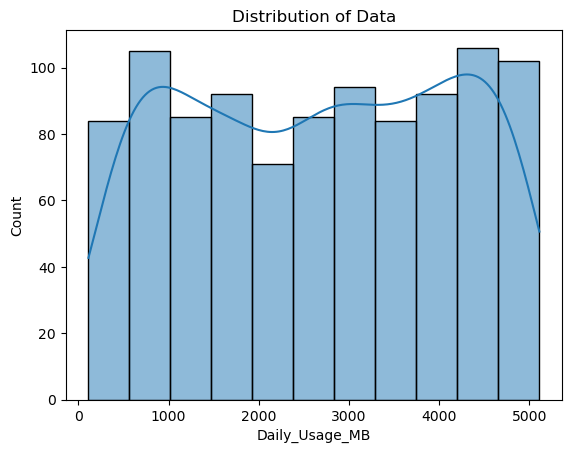

In [10]:
#Understand Distributions
import seaborn as sns
import matplotlib.pyplot as plt

# Distribution of target variable
sns.histplot(df['Daily_Usage_MB'], kde=True)
plt.title('Distribution of Data')
plt.show()

In [11]:

print(df.columns)

Index(['User_ID', 'Name', 'Age', 'Mobile_Number', 'Occupation', 'Location',
       'Daily_Usage_GB', 'Daily_Usage_MB', 'Monthly_Usage_GB', 'Device_Type',
       'Preferred_Network', 'SIM_Type', 'Network_Package', 'Data_Limit_GB',
       'Package_Cost', 'Suggested_Data_Limit_GB', 'Suggested_Package',
       'Suggested_Cost'],
      dtype='object')


In [15]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load your dataset
# Replace 'your_dataset.csv' with your file path
df = pd.read_csv('C:/Users/DELL-7420/OneDrive/Desktop/OCN/User_Data_with_Suggestions(1).csv')

# Identify categorical and numeric columns
categorical_cols = ['Name', 'Occupation', 'Location', 'Device_Type', 'Preferred_Network', 'SIM_Type', 'Network_Package','Suggested_Package']
numeric_cols = ['Age', 'Daily_Usage_GB', 'Daily_Usage_MB', 'Monthly_Usage_GB', 'Data_Limit_GB', 'Package_Cost']

# Separate features and target
X = df.drop(columns=['Suggested_Cost'])  # Replace 'Package_Cost' with your target column name
y = df['Suggested_Cost']

# Preprocessing for numerical and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),  # Scale numeric columns
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)  # Encode categorical columns
    ]
)

# Apply preprocessing
X_processed = preprocessor.fit_transform(X)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42, use_label_encoder=False, eval_metric='rmse'),
    'CatBoost': CatBoostRegressor(verbose=0, random_state=42),
    'SVM': SVR()
}

# Train models and evaluate
results = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append((model_name, mse, r2))

# Display results
results_df = pd.DataFrame(results, columns=['Model', 'MSE', 'R2'])
print(results_df)

C:\Users\DELL-7420\AppData\Roaming\Python\Python312\site-packages\xgboost\core.py:158: UserWarning: [13:01:12] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


               Model           MSE        R2
0  Linear Regression      0.000966  1.000000
1      Decision Tree      0.000000  1.000000
2      Random Forest      4.500000  0.999955
3           AdaBoost      0.000000  1.000000
4            XGBoost      0.189843  0.999998
5           CatBoost     52.915169  0.999473
6                SVM  95730.621360  0.045726


In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Load your dataset
df = pd.read_csv('C:/Users/DELL-7420/OneDrive/Desktop/OCN/User_Data_with_Suggestions(1).csv')

# Identify categorical and numeric columns
categorical_cols = ['Name', 'Occupation', 'Location', 'Device_Type', 'Preferred_Network', 'SIM_Type', 'Network_Package']
numeric_cols = ['Age', 'Daily_Usage_GB', 'Daily_Usage_MB', 'Monthly_Usage_GB', 'Data_Limit_GB']

# Encode the target column
label_encoder = LabelEncoder()
df['Suggested_Package'] = label_encoder.fit_transform(df['Suggested_Package'])

# Separate features and target
X = df.drop(columns=['Suggested_Package'])
y = df['Suggested_Package']

# Preprocessing for numerical and categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),  # Scale numeric columns
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)  # Encode categorical columns
    ]
)

# Apply preprocessing to features
X_processed = preprocessor.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, use_label_encoder=False),
    'CatBoost': CatBoostClassifier(verbose=0, random_state=42),
    'SVM': SVC(probability=True)
}

# Train each model, calculate metrics, and store results
model_names = []
accuracy_scores = []
classification_reports = []

for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    model_names.append(model_name)
    accuracy_scores.append(accuracy)
    classification_reports.append(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Create a DataFrame for the results
results_df = pd.DataFrame({
    'Model': model_names,
    'Accuracy': accuracy_scores
})

# Display results
print(results_df)

# Display classification reports for each model
for i, model_name in enumerate(model_names):
    print(f"\nClassification Report for {model_name}:\n")
    print(classification_reports[i])


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training AdaBoost...


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Preci

Training XGBoost...
Training CatBoost...
Training SVM...
                 Model  Accuracy
0  Logistic Regression     0.880
1        Decision Tree     1.000
2        Random Forest     0.995
3             AdaBoost     0.345
4              XGBoost     0.995
5             CatBoost     1.000
6                  SVM     0.880

Classification Report for Logistic Regression:

                                       precision    recall  f1-score   support

                         Basic+ Calls       0.81      0.87      0.84        15
       Basic+ Calls (Mobile Friendly)       0.67      1.00      0.80        12
             Basic+ Calls (Streaming)       0.67      1.00      0.80        12
                  Entertainment+ Data       0.91      1.00      0.95        20
Entertainment+ Data (Mobile Friendly)       1.00      0.73      0.84        11
      Entertainment+ Data (Streaming)       1.00      0.72      0.84        25
                         Premium Plan       1.00      0.98      0.99        

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\DELL-7420\AppData\Roaming\Python\Python312\site-packages\xgboost\core.py:158: UserWarning: [13:37:58] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0015a694724fa8361-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


ValueError: regplot inputs must be 1d

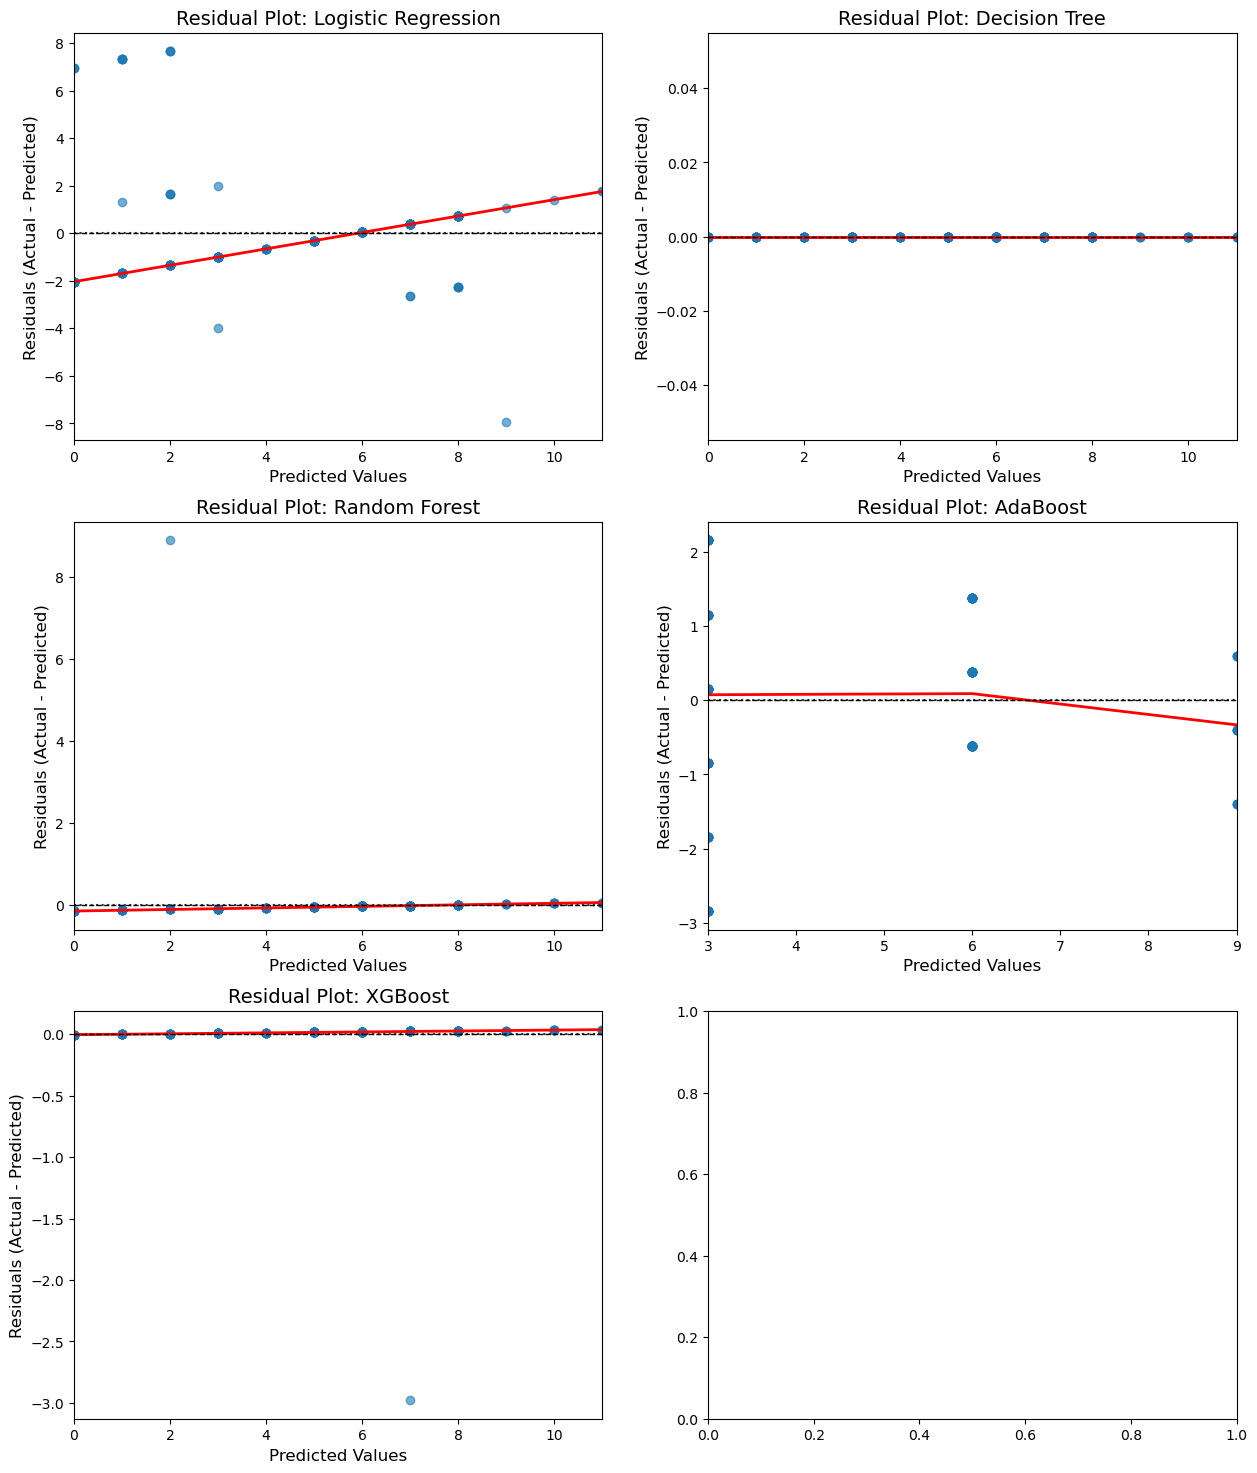

In [23]:
# Encode labels to numeric if they are categorical
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score

# List of models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss'),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=42)
}
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Residual plots
fig, axes = plt.subplots(3, 2, figsize=(15, 18))
axes = axes.flatten()

for idx, (model_name, model) in enumerate(models.items()):
    # Train the model on encoded labels
    model.fit(X_train, y_train_encoded)
    
    # Make predictions
    y_pred_encoded = model.predict(X_test)
    
    # Compute residuals using numeric labels
    residuals = y_test_encoded - y_pred_encoded

    # Plot residuals
    sns.residplot(x=y_pred_encoded, y=residuals, lowess=True, line_kws={'color': 'red', 'lw': 2},
                  scatter_kws={'alpha': 0.6}, ax=axes[idx])
    axes[idx].axhline(y=0, color='black', linestyle='--', linewidth=1)
    axes[idx].set_title(f'Residual Plot: {model_name}', fontsize=14)
    axes[idx].set_xlabel('Predicted Values', fontsize=12)
    axes[idx].set_ylabel('Residuals (Actual - Predicted)', fontsize=12)

# Adjust layout
plt.tight_layout()
plt.show()


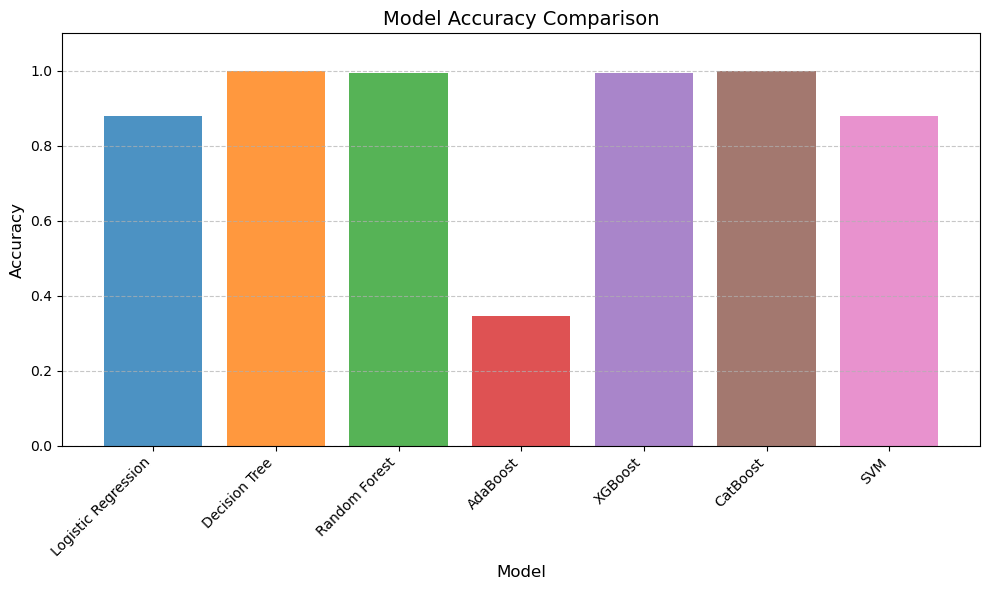

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# Data for the bar chart
data = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost",
        "CatBoost",
        "SVM",
    ],
    "Accuracy": [0.880, 1.000, 0.995, 0.345, 0.995, 1.000, 0.880],
}

# Create a DataFrame
df = pd.DataFrame(data)

# Bar chart
plt.figure(figsize=(10, 6))
colors = plt.cm.tab10(range(len(df["Model"])))  # Generate unique colors
plt.bar(df["Model"], df["Accuracy"], color=colors, alpha=0.8)
plt.xlabel("Model", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.title("Model Accuracy Comparison", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.ylim(0, 1.1)  # Set y-axis limit
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


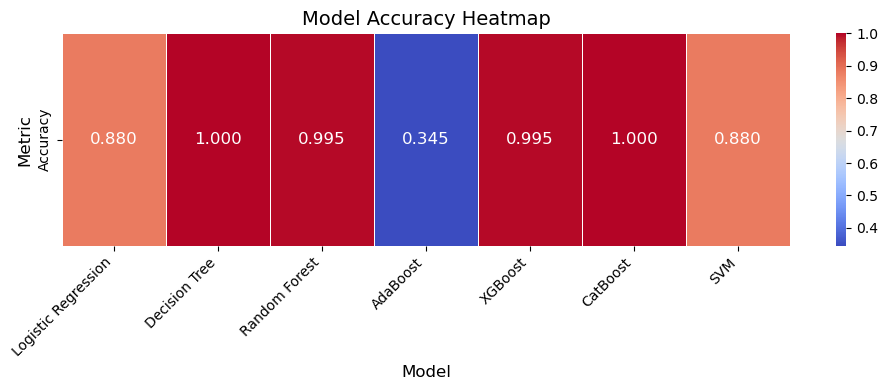

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Data for the heatmap
data = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "AdaBoost",
        "XGBoost",
        "CatBoost",
        "SVM",
    ],
    "Accuracy": [0.880, 1.000, 0.995, 0.345, 0.995, 1.000, 0.880],
}

# Create a DataFrame
df = pd.DataFrame(data)

# Pivot for heatmap
heatmap_data = df.set_index("Model").T

# Create the heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    cbar=True,
    linewidths=0.5,
    annot_kws={"size": 12},
)

plt.title("Model Accuracy Heatmap", fontsize=14)
plt.xlabel("Model", fontsize=12)
plt.ylabel("Metric", fontsize=12)
plt.xticks(fontsize=10, rotation=45, ha="right")
plt.yticks(fontsize=10)
plt.tight_layout()

# Show the plot
plt.show()
